In [8]:
import os, re, glob, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import kagglehub
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import MobileNetV2
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, auc,
                             precision_recall_curve, average_precision_score,
                             accuracy_score, precision_score, recall_score,
                             f1_score)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

IMG = 224            # image side used by both models
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE
CLASSES = ["NORMAL", "PNEUMONIA"]          # label 0 / label 1

path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print("Path to dataset files:", path)

def find_root(base):
    """Folder that directly contains train/, val/ and test/ (skips __MACOSX)."""
    for dirpath, dirnames, _ in os.walk(base):
        if "__MACOSX" in dirpath:
            continue
        if {"train", "val", "test"} <= set(dirnames):
            return dirpath
    raise FileNotFoundError("train/val/test folders not found under " + base)

ROOT = find_root(path)
print("Dataset root:", ROOT)


Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Path to dataset files: /kaggle/input/chest-xray-pneumonia
Dataset root: /kaggle/input/chest-xray-pneumonia/chest_xray


In [9]:
def patient_id(fp):
    n = os.path.basename(fp).lower()
    m = re.match(r"(person\d+)", n)             # person1946_bacteria_4874.jpeg
    if m: return m.group(1)
    m = re.search(r"im-(\d{4})", n)             # IM-0115-0001.jpeg / NORMAL2-IM-1427-0001.jpeg
    if m: return "im" + m.group(1)
    return n                                     # fallback: each file is its own group

rows = []
for split in ["train", "val", "test"]:
    for cls in CLASSES:
        for fp in glob.glob(os.path.join(ROOT, split, cls, "*")):
            if not fp.lower().endswith((".jpeg", ".jpg", ".png")):
                continue
            name = os.path.basename(fp).lower()
            if cls == "NORMAL":        sub = "normal"
            elif "bacteria" in name:   sub = "bacteria"
            elif "virus" in name:      sub = "virus"
            else:                      sub = "pneumonia_other"
            rows.append(dict(path=fp, split=split, label=CLASSES.index(cls),
                             subtype=sub, patient=patient_id(fp)))

df = pd.DataFrame(rows)
print(df.groupby(["split", "subtype"]).size().unstack(fill_value=0))
print("Total images:", len(df))

subtype  bacteria  normal  virus
split                           
test          242     234    148
train        2530    1341   1345
val             8       8      0
Total images: 5856


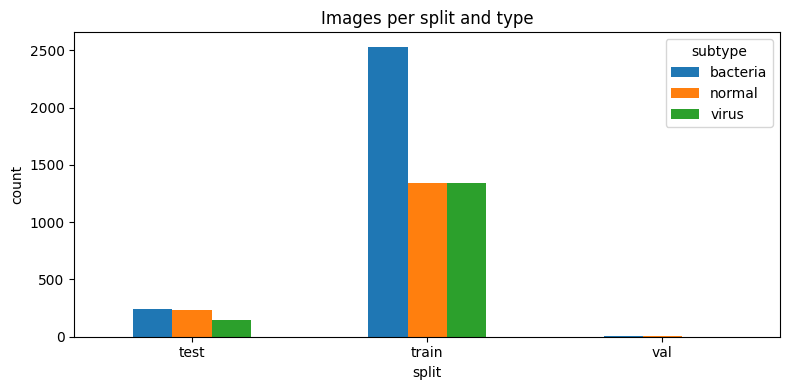

In [10]:
counts = df.groupby(["split", "subtype"]).size().unstack(fill_value=0)
counts.plot(kind="bar", figsize=(8, 4), title="Images per split and type")
plt.ylabel("count"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

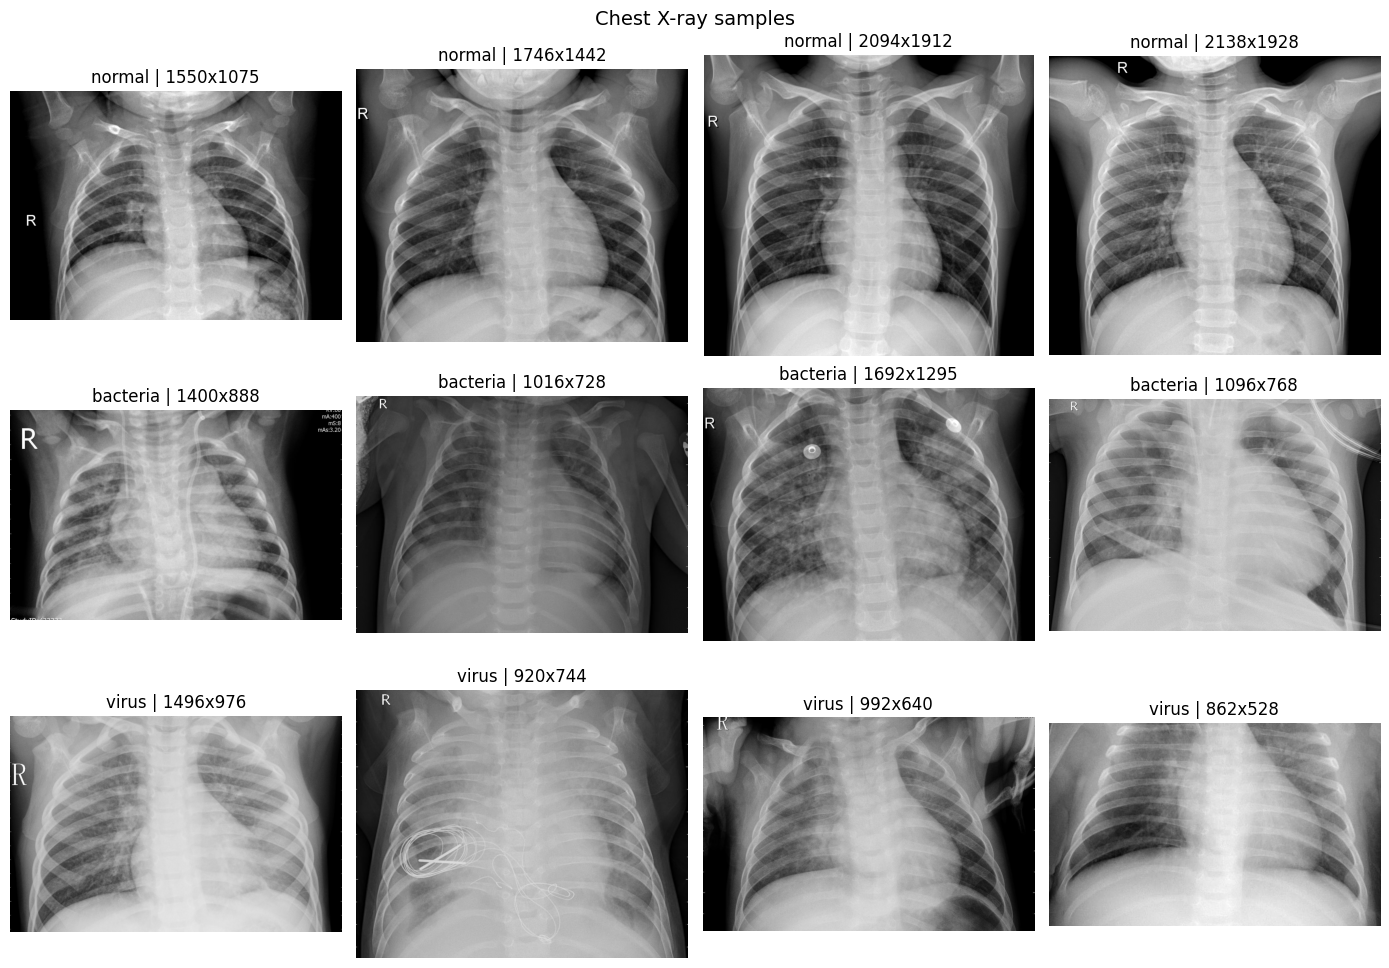

In [11]:
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for r, sub in enumerate(["normal", "bacteria", "virus"]):
    pool = df[(df.subtype == sub) & (df.split == "train")].path.tolist()
    for c, fp in enumerate(random.sample(pool, 4)):
        im = Image.open(fp).convert("L")
        axes[r, c].imshow(im, cmap="gray")
        axes[r, c].set_title(f"{sub} | {im.size[0]}x{im.size[1]}")
        axes[r, c].axis("off")
plt.suptitle("Chest X-ray samples", fontsize=14)
plt.tight_layout(); plt.show()

In [12]:
sizes = [Image.open(p).size for p in df.sample(400, random_state=SEED).path]
w, h = zip(*sizes)
print(f"Width  min/median/max: {min(w)}/{int(np.median(w))}/{max(w)}")
print(f"Height min/median/max: {min(h)}/{int(np.median(h))}/{max(h)}")

Width  min/median/max: 462/1272/2721
Height min/median/max: 189/888/2663


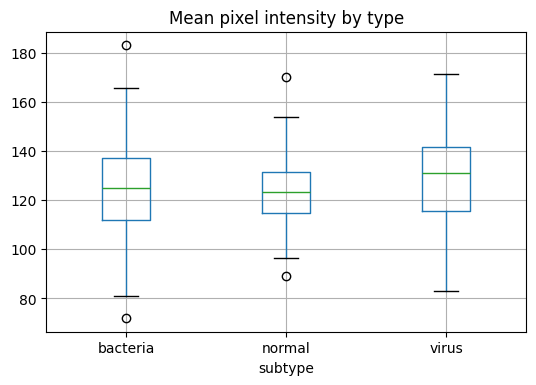

In [13]:
def mean_intensity(fp):
    return np.asarray(Image.open(fp).convert("L").resize((64, 64))).mean()
sample = df[df.split == "train"].sample(300, random_state=SEED)
sample["intensity"] = sample.path.map(mean_intensity)
sample.boxplot(column="intensity", by="subtype", figsize=(6, 4))
plt.suptitle(""); plt.title("Mean pixel intensity by type"); plt.show()

In [14]:
dev = df[df.split.isin(["train", "val"])].reset_index(drop=True)   # train + tiny val
test_df = df[df.split == "test"].reset_index(drop=True)            # untouched

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
tr_idx, va_idx = next(sgkf.split(dev, dev.label, groups=dev.patient))
train_df, val_df = dev.iloc[tr_idx].reset_index(drop=True), dev.iloc[va_idx].reset_index(drop=True)

assert set(train_df.patient).isdisjoint(set(val_df.patient)), "patient leakage!"
print(f"train {len(train_df)} | val {len(val_df)} | test {len(test_df)}")
print("train pneumonia ratio:", round(train_df.label.mean(), 3),
      "| val:", round(val_df.label.mean(), 3), "| test:", round(test_df.label.mean(), 3))

def load_image(fp, label):
    x = tf.io.read_file(fp)
    x = tf.io.decode_image(x, channels=3, expand_animations=False)
    x.set_shape([None, None, 3])
    x = tf.image.resize(x, (IMG, IMG))                 # float32, range 0-255
    return x, tf.reshape(tf.cast(label, tf.float32), [1])

def make_ds(d, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((list(d.path), d.label.values))
    if shuffle:
        ds = ds.shuffle(len(d), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(load_image, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(train_df, shuffle=True)
val_ds = make_ds(val_df)
test_ds = make_ds(test_df)

train 4182 | val 1050 | test 624
train pneumonia ratio: 0.741 | val: 0.748 | test: 0.625


In [15]:
n0, n1 = (train_df.label == 0).sum(), (train_df.label == 1).sum()
class_weight = {0: len(train_df) / (2 * n0), 1: len(train_df) / (2 * n1)}
print("Class weights:", class_weight)

augment = tf.keras.Sequential([           # active only while training
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomContrast(0.15),
], name="augmentation")

METRICS = ["accuracy",
           tf.keras.metrics.Precision(name="precision"),
           tf.keras.metrics.Recall(name="recall"),
           tf.keras.metrics.AUC(name="auc")]

def cbs(name):
    return [callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
            callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2),
            callbacks.ModelCheckpoint(f"{name}.keras", monitor="val_loss", save_best_only=True)]

def plot_history(hist, title):
    h = hist.history
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    for a, k, t in zip(ax, ["accuracy", "loss", "auc"], ["Accuracy", "Loss", "AUC"]):
        a.plot(h[k], label="train"); a.plot(h["val_" + k], label="val")
        a.set_title(f"{title} - {t}"); a.set_xlabel("epoch"); a.legend()
    plt.tight_layout(); plt.show()


Class weights: {0: np.float64(1.9289667896678966), 1: np.float64(0.6749515816655907)}


Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,361 (1.61 MB)

 Trainable params: 422,401 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

Epoch 1/25
131/131 ━━━━━━━━━━━━━━━━━━━━ 61s 354ms/step - accuracy: 0.8508 - auc: 0.9272 - loss: 0.3391 - precision: 0.9595 - recall: 0.8338 - val_accuracy: 0.7476 - val_auc: 0.5000 - val_loss: 2.7089 - val_precision: 0.7476 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/25
131/131 ━━━━━━━━━━━━━━━━━━━━ 33s 252ms/step - accuracy: 0.8766 - auc: 0.9506 - loss: 0.2792 - precision: 0.9667 - recall: 0.8631 - val_accuracy: 0.7476 - val_auc: 0.5000 - val_loss: 4.0491 - val_precision: 0.7476 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 3/25
131/131 ━━━━━━━━━━━━━━━━━━━━ 42s 261ms/step - accuracy: 0.8955 - auc: 0.9570 - loss: 0.2567 - precision: 0.9726 - recall: 0.8838 - val_accuracy: 0.7476 - val_auc: 0.5075 - val_loss: 2.3006 - val_precision: 0.7476 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 4/25
131/131 ━━━━━━━━━━━━━━━━━━━━ 33s 252ms/step - accuracy: 0.9063 - auc: 0.9701 - loss: 0.2169 - precision: 0.9731 - recall: 0.8983 - val_accuracy: 0.7476 - val_auc: 0.5000 - val_loss: 

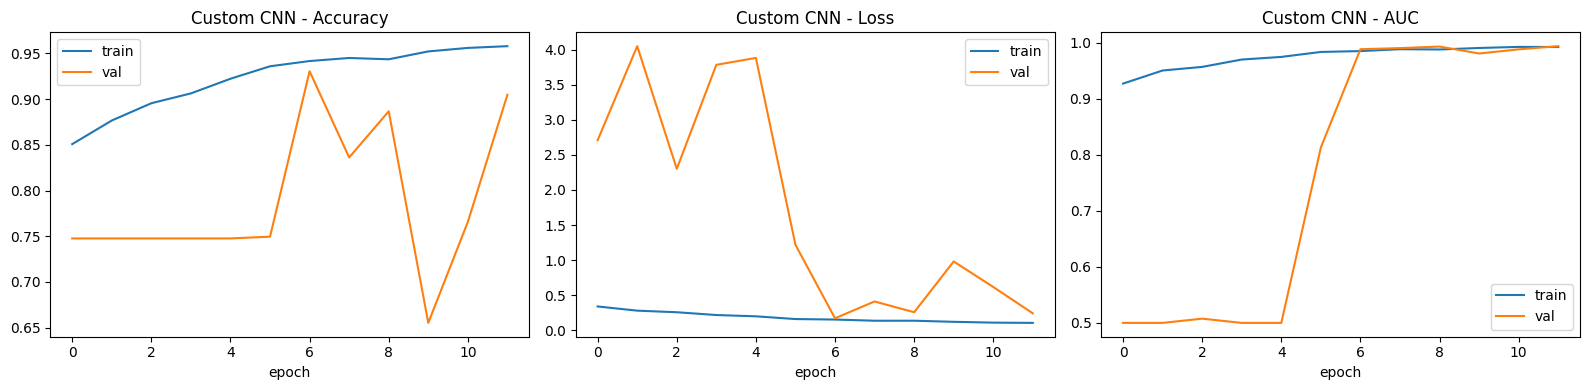

In [16]:
def build_cnn():
    inp = layers.Input((IMG, IMG, 3))
    x = augment(inp)
    x = layers.Rescaling(1 / 255.0)(x)
    for i, f in enumerate([32, 64, 128, 256]):
        x = layers.Conv2D(f, 3, padding="same", activation="relu",
                          name="last_conv" if i == 3 else f"conv{i + 1}")(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return models.Model(inp, out, name="custom_cnn")

cnn = build_cnn()
cnn.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
            loss="binary_crossentropy", metrics=METRICS)
cnn.summary()

hist_cnn = cnn.fit(train_ds, validation_data=val_ds, epochs=25,
                   class_weight=class_weight, callbacks=cbs("custom_cnn"))
plot_history(hist_cnn, "Custom CNN")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 45s 286ms/step - accuracy: 0.8042 - auc: 0.9170 - loss: 0.4154 - precision: 0.9351 - recall: 0.8202 - val_accuracy: 0.9362 - val_auc: 0.9782 - val_loss: 0.1880 - val_precision: 0.9499 - val_recall: 0.9656 - learning_rate: 0.0010
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 34s 261ms/step - accuracy: 0.9079 - auc: 0.9733 - loss: 0.2279 - precision: 0.9725 - recall: 0.9012 - val_accuracy: 0.9476 - val_auc: 0.9795 - val_loss: 0.1603 - val_precision: 0.9679 - val_recall: 0.9618 - learning_rate: 0.0010
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 37s 286ms/step - accuracy: 0.9268 - auc: 0.9810 - loss: 0.1871 - precision: 0.9771 - recall: 0.9229 - val_accuracy: 0.9514 - val_auc: 0.9808 - val_loss: 0.1515 - val_precision: 0.9588 - val_recall: 0.9771 - learning_rate: 0.0010
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 38s 260ms/step - accuracy: 0.9232 - auc: 0.9811 - loss: 0.1814 - precision: 0.9793 - recall: 0.9158 - va

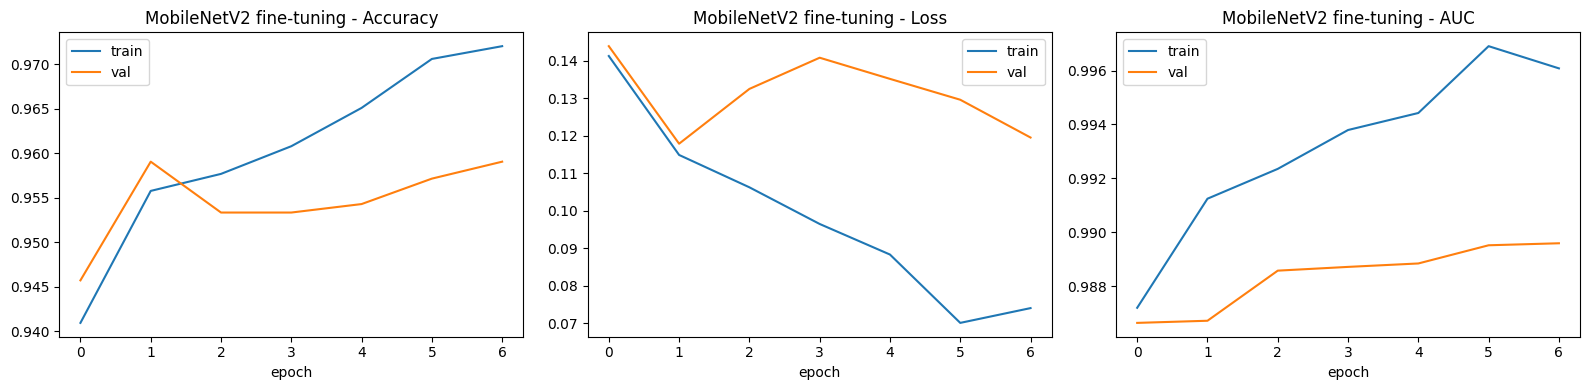

In [17]:
def build_transfer():
    base = MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False, weights="imagenet")
    base.trainable = False                                # stage 1: frozen backbone
    inp = layers.Input((IMG, IMG, 3))
    x = augment(inp)
    x = layers.Rescaling(1 / 127.5, offset=-1)(x)         # MobileNetV2 expects [-1, 1]
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return models.Model(inp, out, name="mobilenetv2_transfer"), base

tl, base = build_transfer()
tl.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
           loss="binary_crossentropy", metrics=METRICS)
hist_tl1 = tl.fit(train_ds, validation_data=val_ds, epochs=10,
                  class_weight=class_weight, callbacks=cbs("transfer_stage1"))

# stage 2: fine-tune the top 30 backbone layers with a small learning rate
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:                                 # keep BatchNorm statistics fixed
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
tl.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
           loss="binary_crossentropy", metrics=METRICS)
hist_tl2 = tl.fit(train_ds, validation_data=val_ds, epochs=10,
                  class_weight=class_weight, callbacks=cbs("transfer_finetuned"))
plot_history(hist_tl2, "MobileNetV2 fine-tuning")

      model  threshold  accuracy  precision  recall  specificity     f1    auc
 Custom CNN       0.50    0.6667     0.6522  1.0000       0.1111 0.7895 0.9402
 Custom CNN tuned 0.95    0.8077     0.7722  0.9821       0.5171 0.8646 0.9402
MobileNetV2       0.50    0.8365     0.7963  0.9923       0.5769 0.8836 0.9709
MobileNetV2 tuned 0.75    0.8558     0.8191  0.9872       0.6368 0.8953 0.9709

===== Custom CNN (threshold 0.5) =====
              precision    recall  f1-score   support

      NORMAL     1.0000    0.1111    0.2000       234
   PNEUMONIA     0.6522    1.0000    0.7895       390

    accuracy                         0.6667       624
   macro avg     0.8261    0.5556    0.4947       624
weighted avg     0.7826    0.6667    0.5684       624



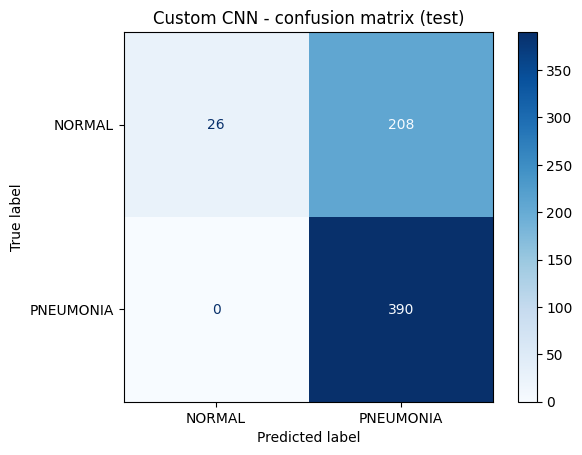


===== MobileNetV2 (threshold 0.5) =====
              precision    recall  f1-score   support

      NORMAL     0.9783    0.5769    0.7258       234
   PNEUMONIA     0.7963    0.9923    0.8836       390

    accuracy                         0.8365       624
   macro avg     0.8873    0.7846    0.8047       624
weighted avg     0.8645    0.8365    0.8244       624



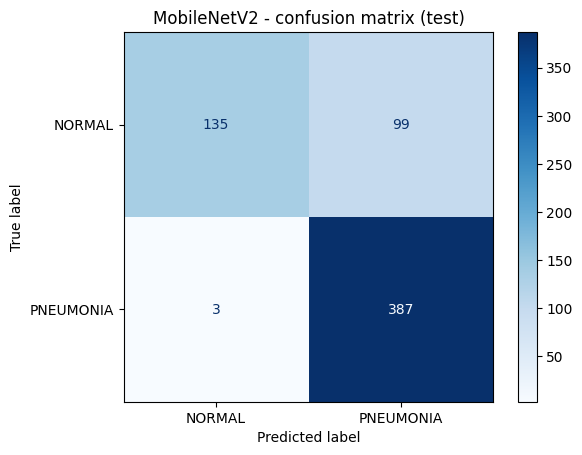

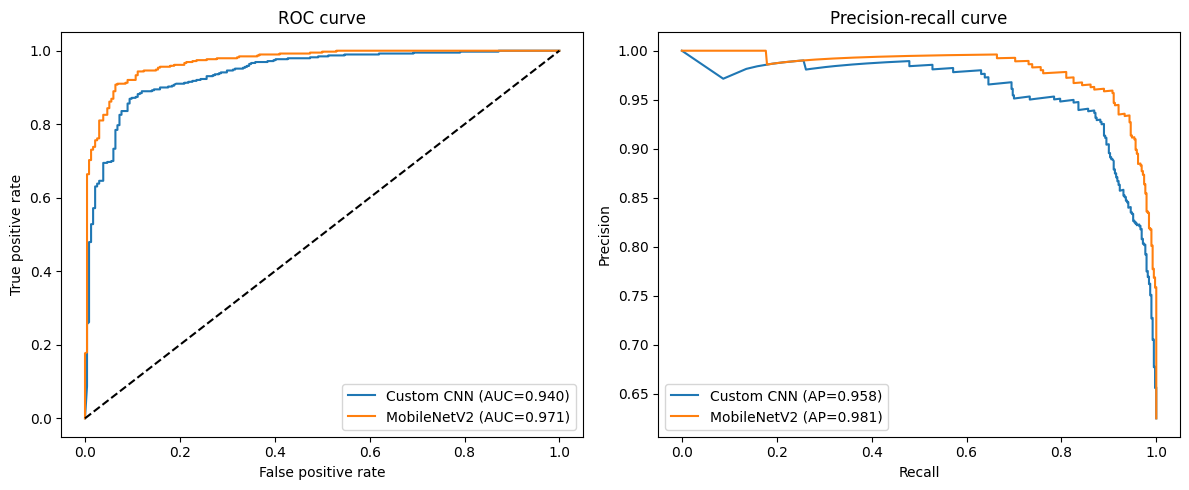

In [18]:
y_val = val_df.label.values
y_test = test_df.label.values

probs = {"Custom CNN": (cnn.predict(val_ds, verbose=0).ravel(), cnn.predict(test_ds, verbose=0).ravel()),
         "MobileNetV2": (tl.predict(val_ds, verbose=0).ravel(), tl.predict(test_ds, verbose=0).ravel())}

def pick_threshold(y, p, target_recall=0.95):
    """Highest-precision threshold on the VALIDATION set that still reaches the target recall."""
    fpr, tpr, thr = roc_curve(y, p)
    return float(thr[np.where(tpr >= target_recall)[0][0]])

summary = []
for name, (pv, pt) in probs.items():
    thr_tuned = pick_threshold(y_val, pv)
    for tag, thr in [("0.50", 0.5), (f"tuned {thr_tuned:.2f}", thr_tuned)]:
        pred = (pt >= thr).astype(int)
        summary.append(dict(model=name, threshold=tag,
                            accuracy=accuracy_score(y_test, pred),
                            precision=precision_score(y_test, pred),
                            recall=recall_score(y_test, pred),
                            specificity=recall_score(y_test, pred, pos_label=0),
                            f1=f1_score(y_test, pred),
                            auc=auc(*roc_curve(y_test, pt)[:2])))
summary = pd.DataFrame(summary).round(4)
print(summary.to_string(index=False))

# detailed report + confusion matrix for each model at 0.5
for name, (_, pt) in probs.items():
    pred = (pt >= 0.5).astype(int)
    print(f"\n===== {name} (threshold 0.5) =====")
    print(classification_report(y_test, pred, target_names=CLASSES, digits=4))
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=CLASSES).plot(cmap="Blues")
    plt.title(f"{name} - confusion matrix (test)"); plt.show()

# ROC and precision-recall curves
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for name, (_, pt) in probs.items():
    fpr, tpr, _ = roc_curve(y_test, pt)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC={auc(fpr, tpr):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, pt)
    ax[1].plot(rc, pr, label=f"{name} (AP={average_precision_score(y_test, pt):.3f})")
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_title("ROC curve")
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].legend()
ax[1].set_title("Precision-recall curve"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].legend()
plt.tight_layout(); plt.show()

Best model: MobileNetV2
          count  fraction predicted PNEUMONIA
subtype                                      
bacteria    242                         0.988
normal      234                         0.423
virus       148                         1.000
(normal row = false-positive rate; bacteria/virus rows = recall for that subtype)


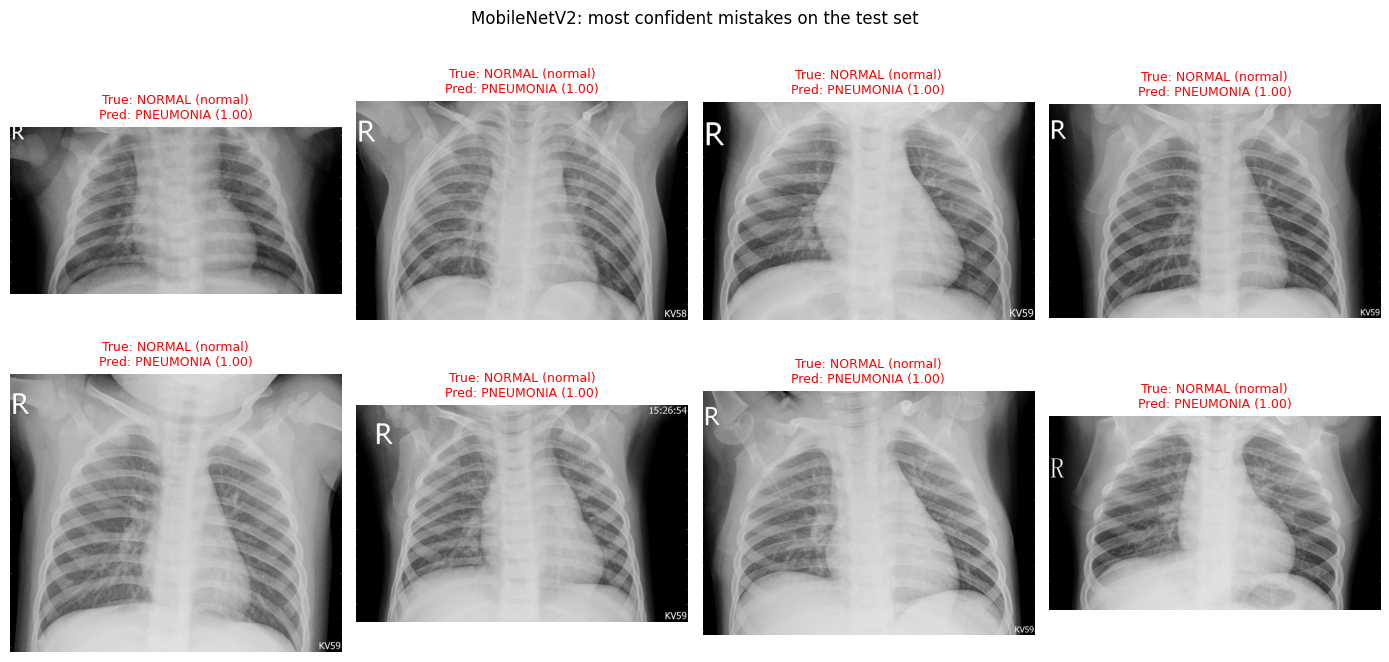

In [19]:
best_name = summary[summary.threshold == "0.50"].sort_values("auc", ascending=False).iloc[0].model
pt_best = probs[best_name][1]
err = test_df.copy()
err["pred"] = (pt_best >= 0.5).astype(int)
err["prob"] = pt_best
print("Best model:", best_name)
print(err.groupby("subtype").pred.agg(["count", "mean"])
         .rename(columns={"mean": "fraction predicted PNEUMONIA"}).round(3))
print("(normal row = false-positive rate; bacteria/virus rows = recall for that subtype)")

# show the worst mistakes
wrong = err[err.pred != err.label].sort_values("prob", key=lambda s: abs(s - 0.5), ascending=False).head(8)
plt.figure(figsize=(14, 7))
for k, (_, r) in enumerate(wrong.iterrows()):
    plt.subplot(2, 4, k + 1)
    plt.imshow(Image.open(r.path).convert("L"), cmap="gray")
    plt.title(f"True: {CLASSES[r.label]} ({r.subtype})\nPred: {CLASSES[r.pred]} ({r.prob:.2f})",
              color="red", fontsize=9)
    plt.axis("off")
plt.suptitle(f"{best_name}: most confident mistakes on the test set")
plt.tight_layout(); plt.show()

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(6, 224, 224, 3))
  warnings.warn(msg)


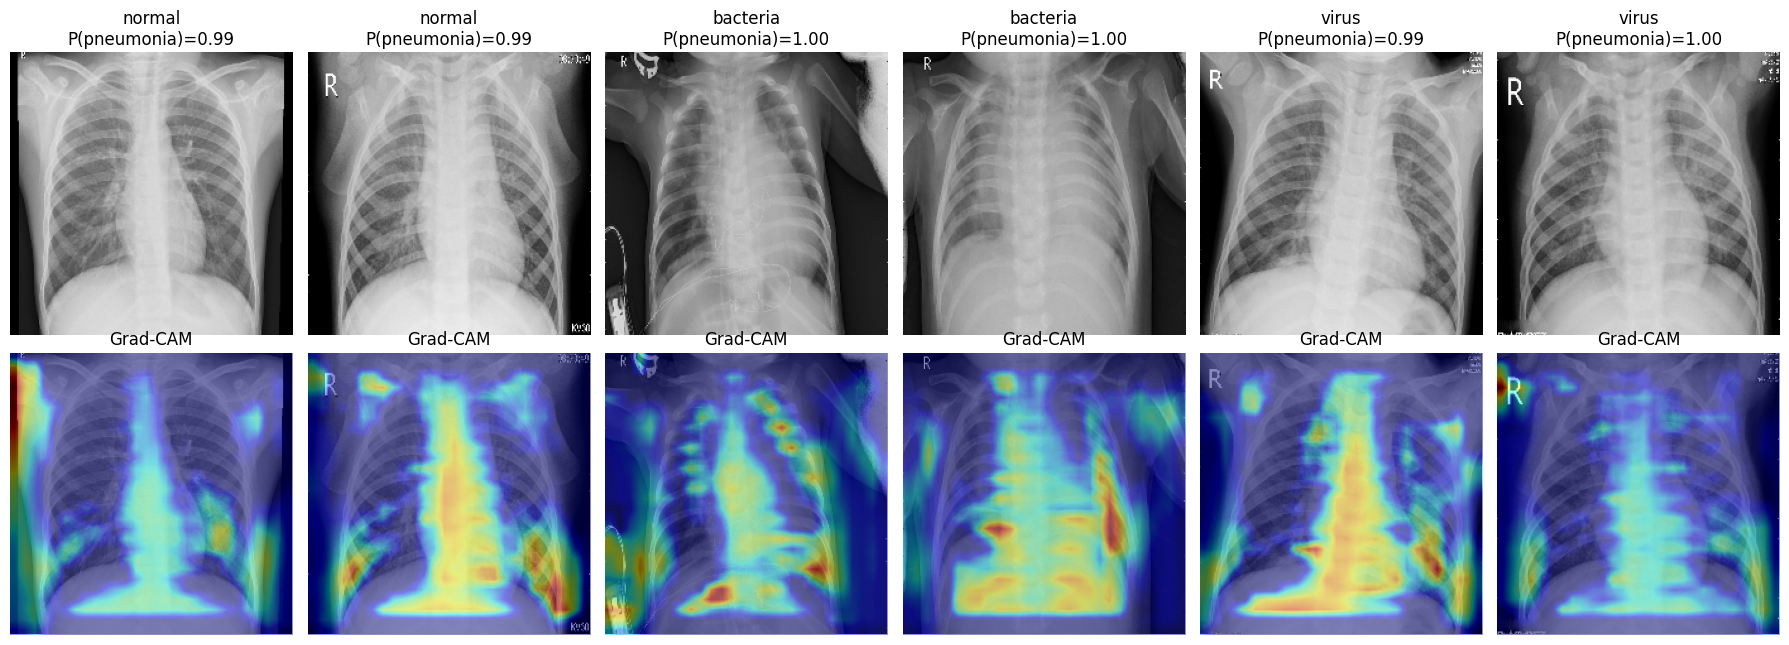

In [20]:
def grad_cam(model, batch, layer_name="last_conv"):
    gm = tf.keras.Model(model.inputs, [model.get_layer(layer_name).output, model.output])
    with tf.GradientTape() as tape:
        conv_out, pred = gm(batch, training=False)
        score = pred[:, 0]
    grads = tape.gradient(score, conv_out)
    weights = tf.reduce_mean(grads, axis=(1, 2))                 # (B, C)
    cam = tf.nn.relu(tf.einsum("bhwc,bc->bhw", conv_out, weights))
    cam = cam / (tf.reduce_max(cam, axis=(1, 2), keepdims=True) + 1e-8)
    return cam.numpy(), pred.numpy().ravel()

pick = pd.concat([test_df[test_df.subtype == s].sample(2, random_state=SEED)
                  for s in ["normal", "bacteria", "virus"]])
imgs = np.stack([load_image(p, 0)[0].numpy() for p in pick.path])
cams, p = grad_cam(cnn, imgs)

fig, axes = plt.subplots(2, 6, figsize=(18, 6.5))
for k in range(6):
    axes[0, k].imshow(imgs[k].astype("uint8")); axes[0, k].axis("off")
    axes[0, k].set_title(f"{pick.subtype.iloc[k]}\nP(pneumonia)={p[k]:.2f}")
    axes[1, k].imshow(imgs[k].astype("uint8"))
    axes[1, k].imshow(cams[k], cmap="jet", alpha=0.45, extent=(0, IMG, IMG, 0), interpolation="bilinear")
    axes[1, k].axis("off"); axes[1, k].set_title("Grad-CAM")
plt.tight_layout(); plt.show()

In [21]:
cnn.save("pneumonia_custom_cnn.keras")
tl.save("pneumonia_mobilenetv2.keras")
print("Models saved.")

Models saved.
